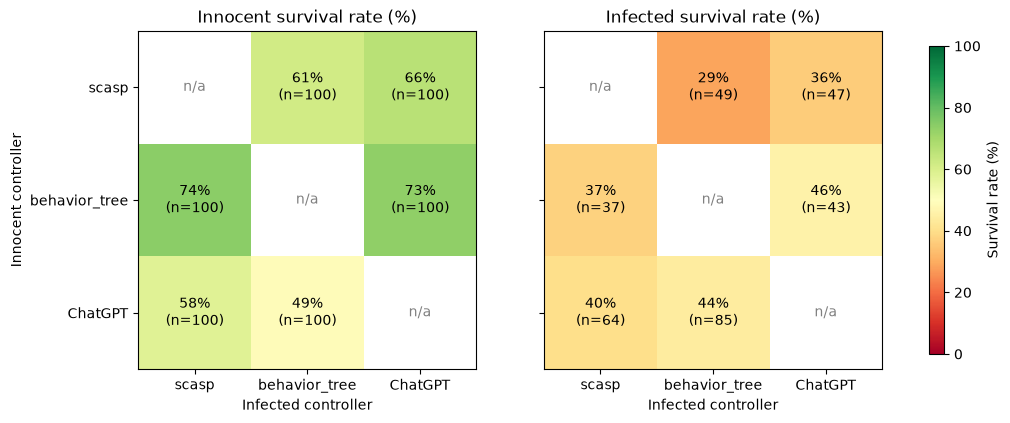

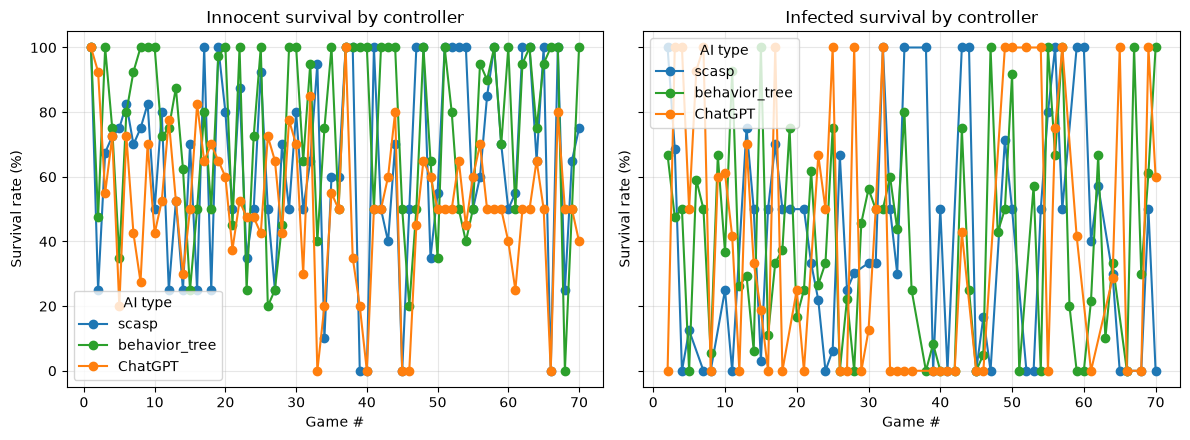

Average scasp_action_query_latency_ms: 473.33 ms (over 298 rows)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_PATH = "gamesFinale.csv"   # <- change to your file

# role_mapping uses "ChatGPT"; column prefixes use "llm"
COLUMN_PREFIX = {"scasp": "scasp", "behavior_tree": "behavior_tree", "ChatGPT": "llm"}
AI_ORDER = ["scasp", "behavior_tree", "ChatGPT"]
COLORS = {"scasp": "tab:blue", "behavior_tree": "tab:green", "ChatGPT": "tab:orange"}

df = pd.read_csv(CSV_PATH)

# Parse "innocent:scasp/half_zombie:ChatGPT" into two columns
roles = df["role_mapping"].str.extract(r"innocent:(?P<innocent_ai>[^/]+)/half_zombie:(?P<zombie_ai>.+)")
df = pd.concat([df, roles], axis=1)

PREFIXES = ["scasp", "behavior_tree", "llm"]

def survival(row, role):
    """alive/total for `role` ('innocents' or 'half_zombies').
    Which backend's columns hold a role's counts varies by configuration, and the other
    backends' columns are 0 for that role, so summing across all prefixes is safe."""
    total = sum(row[f"{p}_{role}_total"] for p in PREFIXES)
    alive = sum(row[f"{p}_{role}_alive"] for p in PREFIXES)
    return alive / total if total > 0 else np.nan

df["innocent_survival"] = df.apply(survival, axis=1, role="innocents")
df["zombie_survival"] = df.apply(survival, axis=1, role="half_zombies")

# ---------- Survival-rate matrices (side by side) ----------
def survival_matrix(col):
    mean = df.pivot_table(index="innocent_ai", columns="zombie_ai", values=col, aggfunc="mean")
    n = df.pivot_table(index="innocent_ai", columns="zombie_ai", values=col, aggfunc="count")
    return mean.reindex(index=AI_ORDER, columns=AI_ORDER), n.reindex(index=AI_ORDER, columns=AI_ORDER)

panels = [("innocent_survival", "Innocent survival rate (%)"),
          ("zombie_survival", "Infected survival rate (%)")]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (col, title) in zip(axes, panels):
    mat, cnt = survival_matrix(col)
    im = ax.imshow(mat.values * 100, cmap="RdYlGn", vmin=0, vmax=100)
    ax.set_xticks(range(len(AI_ORDER)), AI_ORDER)
    ax.set_yticks(range(len(AI_ORDER)), AI_ORDER)
    ax.set_xlabel("Infected controller")
    ax.set_title(title)
    for i in range(len(AI_ORDER)):
        for j in range(len(AI_ORDER)):
            v, n = mat.values[i, j], cnt.values[i, j]
            if np.isnan(v) or n == 0:
                ax.text(j, i, "n/a", ha="center", va="center", color="gray")
            else:
                ax.text(j, i, f"{v*100:.0f}%\n(n={int(n)})", ha="center", va="center", color="black")
axes[0].set_ylabel("Innocent controller")
fig.colorbar(im, ax=axes, label="Survival rate (%)", shrink=0.8)
plt.show()

# ---------- Survival rate by game ----------
def plot_survival(ax, ai_col, surv_col, title):
    for ai in AI_ORDER:
        sub = df[df[ai_col] == ai].dropna(subset=[surv_col])
        if sub.empty:
            continue  # this AI never played this role
        per_game = sub.groupby("game")[surv_col].mean().sort_index() * 100
        ax.plot(per_game.index, per_game.values, marker="o", linestyle="-",
                color=COLORS[ai], label=ai)
    ax.set_title(title)
    ax.set_xlabel("Game #")
    ax.set_ylabel("Survival rate (%)")
    ax.set_ylim(-5, 105)
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.grid(alpha=0.3)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(title="AI type")
    else:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
plot_survival(axes[0], "innocent_ai", "innocent_survival", "Innocent survival by controller")
plot_survival(axes[1], "zombie_ai", "zombie_survival", "Infected survival by controller")
plt.tight_layout()
plt.show()


col = "scasp_action_query_latency_ms"
avg = df[col].mean()   # blank cells (rows where s(CASP) wasn't playing) are skipped automatically
print(f"Average {col}: {avg:.2f} ms (over {df[col].notna().sum()} rows)")